In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("walmart.csv")
df=df.drop("Date", axis=1)
display(df)

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...
6430,45,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,718125.53,0,56.47,3.969,192.330854,8.667


In [3]:
df["Weekly_Sales"] = df["Weekly_Sales"].fillna(df["Weekly_Sales"].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop("Weekly_Sales", axis=1)
y = df["Weekly_Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

display(X_train)


array([[-1.16466588, -0.26842748,  0.8057783 , -1.71088305,  1.10380441,
        -0.8978744 ],
       [-1.24165623, -0.26842748, -2.15108453,  0.01856676,  0.52254808,
         0.43847483],
       [ 1.45300579, -0.26842748,  0.04355515, -0.51121407, -1.14613429,
         0.53724615],
       ...,
       [ 1.06805407, -0.26842748,  1.42237786,  0.70158997,  1.08899892,
         0.09624556],
       [ 1.14504441,  3.72540101, -0.85508863,  0.14116067, -1.05635133,
         2.61251161],
       [-1.24165623, -0.26842748, -1.79487513, -1.78093671,  0.4582488 ,
         0.54311904]], shape=(5148, 6))

Обучающая выборка имеет 5148 строк и 6 аттрибутов.

In [4]:
median_class = y_train.median()
y_train_class = (y_train > median_class).astype(int)
y_test_class = (y_test > median_class).astype(int)
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)
sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

results_class = pd.DataFrame(
    {
        "Вероятность (Сигмоида)": sample_probs,
        "Класс (Порог 0.5)": sample_preds,
        "Факт (Реальность)": y_test_class.iloc[:5].values,
    }
)
display(results_class.round(3))
print(f"Accuracy: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт (Реальность)
0,0.622,1,1
1,0.565,1,1
2,0.611,1,1
3,0.553,1,1
4,0.286,0,0


Accuracy: 0.6434


Выборка делит метрику на 2 класса, где выясняется выше ли порога в 0.5 или ниже недельные продажи.

In [5]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    eta0=0.01,
    learning_rate="adaptive",
    random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический) : RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:.4f} | Время = {time_ols:.5f} сек")
print(f"SGD (Итеративный)   : RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:.4f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический) : RMSE = $523,884.74 | R2 = 0.1481 | Время = 0.00199 сек
SGD (Итеративный)   : RMSE = $523,883.64 | R2 = 0.1481 | Время = 0.09873 сек


Я пришел к выводу, что метрики одинаковые

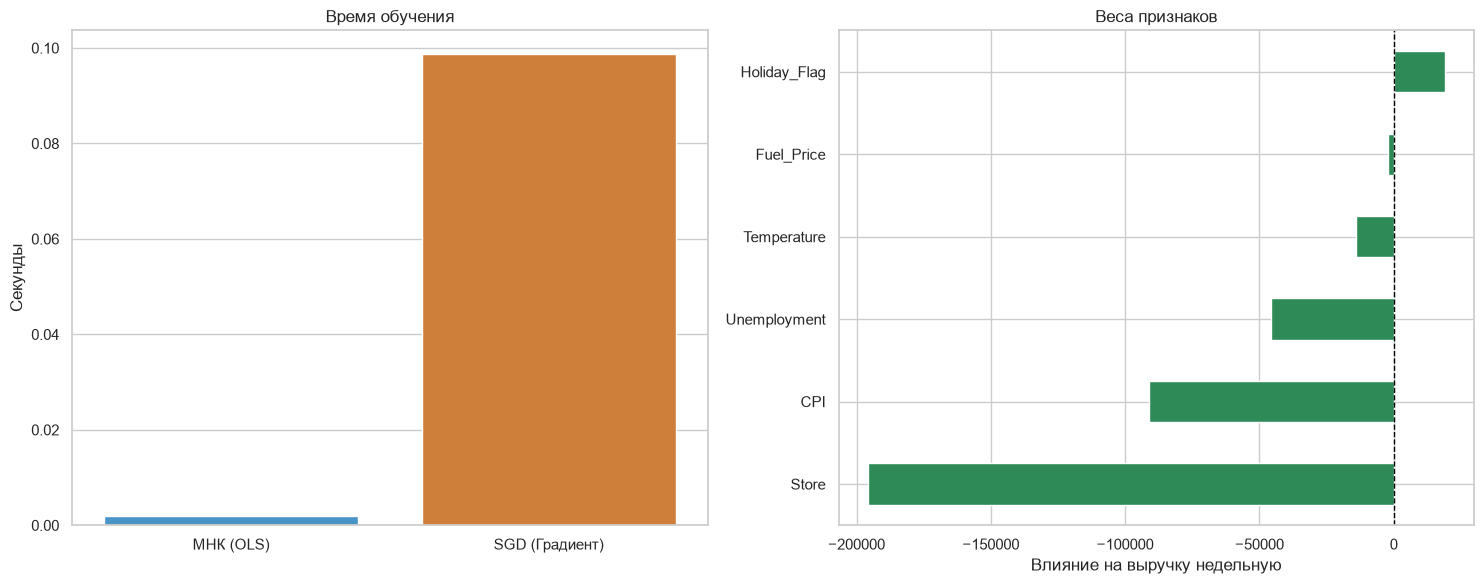

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    x=["МНК (OLS)", "SGD (Градиент)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
    palette=["#3498db", "#e67e22"],
    hue=["МНК (OLS)", "SGD (Градиент)"],
)
axes[0].set_title("Время обучения")
axes[0].set_ylabel("Секунды")

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].axvline(0, color="black", linestyle="--", lw=1)
axes[1].set_title("Веса признаков")
axes[1].set_xlabel("Влияние на выручку недельную")

plt.tight_layout()
plt.show()

На недельную выручку положительно влияют лишь выходные